
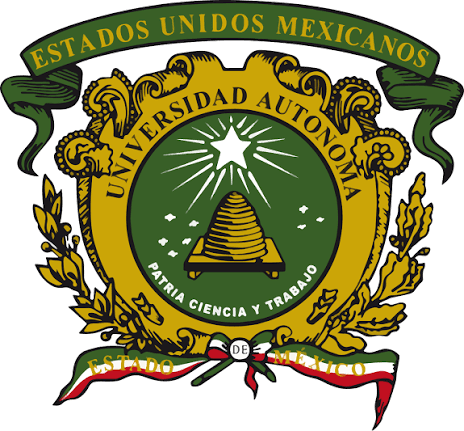

In [9]:
from pathlib import Path
from base64 import b64encode
from IPython.display import HTML, display

# Edita aquí los datos de la portada.
campus = "Centro Universitario UAEM Zumpango"
semestre = "5.º semestre"
turno = "Turno matutino"
asignatura = "Investigación de Operaciones"
practica = "Práctica 2 · Ruta crítica (PERT/CPM)"
proyecto = "Instalación de una red en un laboratorio de cómputo"

integrantes = [
    "Daniela Cacahuatitla García",
    "Alexander Garcia Gonzales",
    "Rafael Mimbrera Moreno"
]

# Insertar el escudo dentro de la portada.
archivo_escudo = Path("escudo_uaem.png")

if archivo_escudo.is_file():
    imagen = b64encode(archivo_escudo.read_bytes()).decode("ascii")
    escudo = (
        f'<img src="data:image/png;base64,{imagen}" '
        'alt="Escudo de la UAEMéx" '
        'style="width:120px; max-width:27%; height:auto;">'
    )
else:
    escudo = '<div style="color:#2e501d; font-weight:bold;">UAEMéx</div>'

nombres = "<br>".join(integrantes)

portada = f"""
<div style="
    box-sizing:border-box;
    position:relative;
    max-width:760px;
    min-height:790px;
    margin:16px auto;
    padding:52px 35px 50px 65px;
    background:#ffffff;
    color:#171717;
    font-family:Arial, sans-serif;
    text-align:center;
    border:1px solid #dddddd;
">
    <div style="
        position:absolute; top:0; bottom:0; left:0;
        width:30px; background:#2e501d;
        border-right:10px solid #aa8b30;
    "></div>

    <div style="
        display:flex; align-items:center; justify-content:center;
        gap:20px; margin-bottom:45px;
    ">
        {escudo}
        <div style="font-size:20px; font-weight:bold; line-height:1.35;">
            Universidad Autónoma del Estado de México
        </div>
    </div>

    <div style="font-size:17px; font-weight:bold; color:#2e501d;">
        {campus.upper()}
    </div>

    <div style="margin-top:36px; font-size:16px; line-height:1.8;">
        <strong>{semestre}</strong><br>
        {turno}
    </div>

    <div style="margin-top:32px; font-size:18px; font-weight:bold;">
        {asignatura}
    </div>

    <h1 style="margin:14px 0 8px; font-size:28px; color:#2e501d;">
        {practica}
    </h1>

    <div style="font-size:17px;">{proyecto}</div>

    <div style="margin-top:44px; font-size:16px; line-height:1.8;">
        <strong>Integrantes</strong><br>
        {nombres}
    </div>
</div>
"""

display(HTML(portada))

## Instalación de una red en un laboratorio de cómputo

### Planteamiento del problema

Se planea instalar una red en un laboratorio de cómputo del Centro Universitario UAEM Zumpango para conectar sus computadoras. El proyecto abarca diez actividades, desde el levantamiento de requerimientos y la revisión del inventario hasta la documentación de la instalación y la entrega del laboratorio. Para organizar el trabajo, se necesita conocer en qué orden se pueden realizar las actividades y cuánto tiempo tomará completar el proyecto.

Algunas actividades pueden realizarse al mismo tiempo. Por ejemplo, el levantamiento de requerimientos y la revisión del inventario pueden comenzar desde el primer día porque ninguna depende de la otra. En cambio, la instalación de canaletas y cableado solo puede iniciar cuando se hayan terminado el diseño de la red y la obtención de los materiales. De manera similar, para configurar y probar la red es necesario que los equipos ya estén conectados al cableado y que su configuración se haya preparado.

Para representar estas relaciones se construirá una red de precedencias. Cada nodo corresponderá a una actividad y las flechas indicarán cuáles deben terminar antes de que otras puedan comenzar. Las duraciones asignadas son hipotéticas, fijas y están expresadas en días.

### Objetivo

Aplicar el método de la ruta crítica (CPM) para calcular la duración mínima del proyecto, identificar las actividades que determinan la fecha de entrega y calcular la holgura total de cada actividad.

Primero se hará un recorrido hacia adelante para calcular el inicio y el fin temprano de cada actividad. Después se hará un recorrido hacia atrás para obtener su inicio y fin tardío. Con esos tiempos se calculará la holgura, que indica el margen de retraso disponible sin mover la fecha de finalización del proyecto.

Por último, se identificará la ruta crítica y se resaltará en la gráfica de la red. Esto permitirá distinguir las actividades que requieren mayor seguimiento, ya que un retraso en cualquiera de ellas puede posponer la entrega del laboratorio.

## Datos del proyecto

Cada actividad tiene una clave, una duración y una lista de
predecesoras. Una actividad puede comenzar cuando todas sus
predecesoras hayan terminado. En la red, una flecha de A a C
indica que C debe esperar a que termine A.

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

actividades = {
    "A": ("Levantar requerimientos", 2, []),
    "B": ("Revisar el inventario", 3, []),
    "C": ("Diseñar la red", 4, ["A"]),
    "D": ("Conseguir materiales", 2, ["B"]),
    "E": ("Instalar canaletas y cableado", 5, ["C", "D"]),
    "F": ("Preparar la configuración de los equipos", 2, ["C"]),
    "G": ("Conectar los equipos al cableado", 4, ["E"]),
    "H": ("Configurar y probar la red", 3, ["F", "G"]),
    "I": ("Documentar la instalación", 2, ["H"]),
    "J": ("Entregar el laboratorio", 1, ["I"])
}

red = nx.DiGraph()

for clave, (nombre, dias, predecesoras) in actividades.items():
    red.add_node(clave, duracion=dias)
    for anterior in predecesoras:
        red.add_edge(anterior, clave)

tabla = pd.DataFrame([
    [clave, nombre, dias, ", ".join(predecesoras) or "Ninguna"]
    for clave, (nombre, dias, predecesoras) in actividades.items()
], columns=["Clave", "Actividad", "Duración (días)", "Predecesoras"])

display(tabla)

,Clave,Actividad,Duración (días),Predecesoras
0,A,Levantar requerimientos,2,Ninguna
1,B,Revisar el inventario,3,Ninguna
2,C,Diseñar la red,4,A
3,D,Conseguir materiales,2,B
4,E,Instalar canaletas y cableado,5,"C, D"
5,F,Preparar la configuración de los equipos,2,C
6,G,Conectar los equipos al cableado,4,E
7,H,Configurar y probar la red,3,"F, G"
8,I,Documentar la instalación,2,H
9,J,Entregar el laboratorio,1,I


## Red de precedencias

Los nodos representan actividades y las flechas indican el orden
en que pueden realizarse. Debajo de cada clave se muestra su duración.
Mantendremos las mismas posiciones en las gráficas de cada etapa.

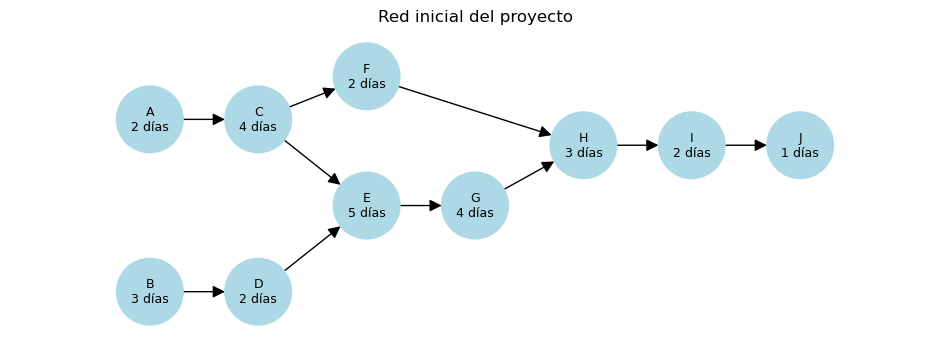

In [3]:
posiciones = {
    "A": (0, 1), "B": (0, -1),
    "C": (1, 1), "D": (1, -1),
    "E": (2, 0), "F": (2, 1.5),
    "G": (3, 0), "H": (4, 0.7),
    "I": (5, 0.7), "J": (6, 0.7)
}

def dibujar_red(titulo, etiquetas, ruta=None):
    ruta = ruta or []
    plt.figure(figsize=(12, 4))

    colores = ["#fca5a5" if nodo in ruta else "lightblue" for nodo in red]
    nx.draw_networkx(
        red, posiciones, labels=etiquetas, node_color=colores,
        node_size=2300, font_size=9, arrows=True, arrowsize=18
    )

    if ruta:
        enlaces_criticos = list(zip(ruta, ruta[1:]))
        nx.draw_networkx_edges(
            red, posiciones, edgelist=enlaces_criticos,
            edge_color="#b91c1c", width=3, arrowsize=20, node_size=2300
        )

    plt.title(titulo)
    plt.margins(0.15)
    plt.axis("off")
    plt.show()

etiquetas = {
    nodo: f"{nodo}\n{red.nodes[nodo]['duracion']} días" for nodo in red
}
dibujar_red("Red inicial del proyecto", etiquetas)

## Recorrido hacia adelante

Calculamos los tiempos tempranos desde el inicio del proyecto.

- **IT (inicio temprano):** es 0 si la actividad no tiene predecesoras.
  Si tiene varias, se toma el mayor fin temprano de sus predecesoras.
- **FT (fin temprano):** se obtiene sumando la duración al inicio temprano.

Por ejemplo, C termina en el día 6 y D en el día 5. Como E necesita
que ambas terminen, E inicia en el día 6. Su duración es de 5 días,
por lo que termina en el día 11.

A: IT = 0, FT = 0 + 2 = 2
B: IT = 0, FT = 0 + 3 = 3
C: IT = 2, FT = 2 + 4 = 6
D: IT = 3, FT = 3 + 2 = 5
F: IT = 6, FT = 6 + 2 = 8
E: IT = 6, FT = 6 + 5 = 11
G: IT = 11, FT = 11 + 4 = 15
H: IT = 15, FT = 15 + 3 = 18
I: IT = 18, FT = 18 + 2 = 20
J: IT = 20, FT = 20 + 1 = 21

Duración del proyecto: 21 días


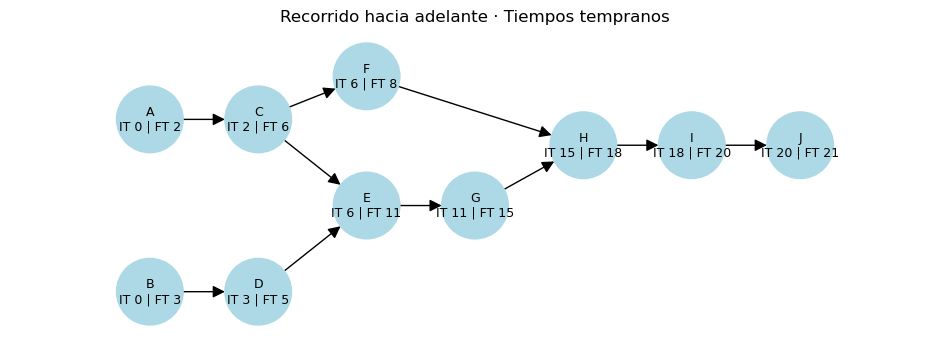

In [4]:
orden = list(nx.topological_sort(red))
inicio_temprano = {}
fin_temprano = {}

for nodo in orden:
    inicio_temprano[nodo] = max(
        (fin_temprano[anterior] for anterior in red.predecessors(nodo)),
        default=0
    )
    duracion = red.nodes[nodo]["duracion"]
    fin_temprano[nodo] = inicio_temprano[nodo] + duracion
    print(f"{nodo}: IT = {inicio_temprano[nodo]}, "
          f"FT = {inicio_temprano[nodo]} + {duracion} = {fin_temprano[nodo]}")

duracion_proyecto = max(fin_temprano.values())
print(f"\nDuración del proyecto: {duracion_proyecto} días")

etiquetas = {
    nodo: f"{nodo}\nIT {inicio_temprano[nodo]} | FT {fin_temprano[nodo]}"
    for nodo in red
}
dibujar_red("Recorrido hacia adelante · Tiempos tempranos", etiquetas)

## Recorrido hacia atrás

Calculamos los tiempos tardíos desde el final del proyecto.

- **FL (fin tardío):** para la actividad final es igual a la duración
  del proyecto. Si una actividad tiene varias sucesoras, se toma
  el menor inicio tardío de esas sucesoras.
- **IL (inicio tardío):** se obtiene restando la duración al fin tardío.

Por ejemplo, J termina como máximo en el día 21. Como dura 1 día,
su inicio tardío es el día 20.

J: FL = 21, IL = 21 - 1 = 20
I: FL = 20, IL = 20 - 2 = 18
H: FL = 18, IL = 18 - 3 = 15
G: FL = 15, IL = 15 - 4 = 11
E: FL = 11, IL = 11 - 5 = 6
F: FL = 15, IL = 15 - 2 = 13
D: FL = 6, IL = 6 - 2 = 4
C: FL = 6, IL = 6 - 4 = 2
B: FL = 4, IL = 4 - 3 = 1
A: FL = 2, IL = 2 - 2 = 0


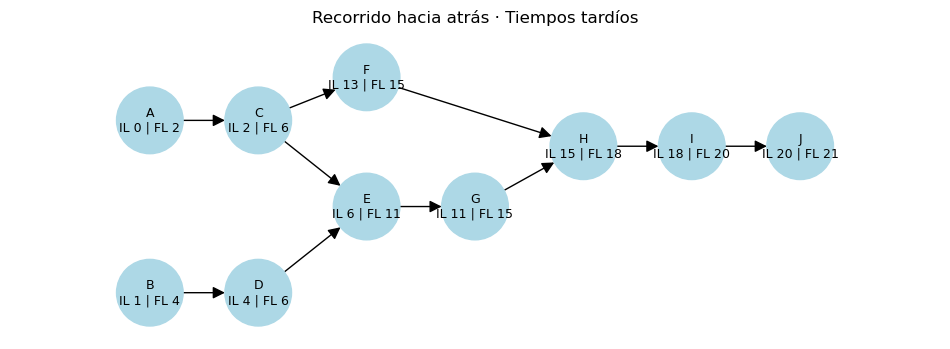

In [5]:
inicio_tardio = {}
fin_tardio = {}

for nodo in reversed(orden):
    fin_tardio[nodo] = min(
        (inicio_tardio[siguiente] for siguiente in red.successors(nodo)),
        default=duracion_proyecto
    )
    duracion = red.nodes[nodo]["duracion"]
    inicio_tardio[nodo] = fin_tardio[nodo] - duracion
    print(f"{nodo}: FL = {fin_tardio[nodo]}, "
          f"IL = {fin_tardio[nodo]} - {duracion} = {inicio_tardio[nodo]}")

etiquetas = {
    nodo: f"{nodo}\nIL {inicio_tardio[nodo]} | FL {fin_tardio[nodo]}"
    for nodo in red
}
dibujar_red("Recorrido hacia atrás · Tiempos tardíos", etiquetas)

## Holguras y ruta crítica

La holgura total se obtiene restando el inicio temprano al inicio
tardío: **Holgura = IL − IT**. También se puede calcular como **FL − FT**.

Una actividad con holgura cero es crítica. La ruta crítica es el
camino de mayor duración entre el inicio y el fin del proyecto.
En la gráfica final se resalta en rojo.

,Actividad,Duración,IT,FT,IL,FL,Holgura,Crítica
0,A,2,0,2,0,2,0,Sí
1,B,3,0,3,1,4,1,No
2,C,4,2,6,2,6,0,Sí
3,D,2,3,5,4,6,1,No
4,E,5,6,11,6,11,0,Sí
5,F,2,6,8,13,15,7,No
6,G,4,11,15,11,15,0,Sí
7,H,3,15,18,15,18,0,Sí
8,I,2,18,20,18,20,0,Sí
9,J,1,20,21,20,21,0,Sí


Ruta crítica: A → C → E → G → H → I → J
Duración total: 21 días


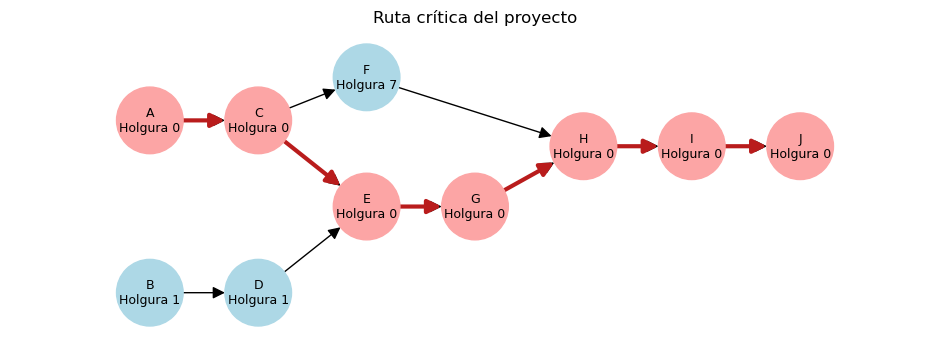

In [6]:
holguras = {
    nodo: inicio_tardio[nodo] - inicio_temprano[nodo] for nodo in red
}

resultados = pd.DataFrame([
    [
        nodo, red.nodes[nodo]["duracion"], inicio_temprano[nodo],
        fin_temprano[nodo], inicio_tardio[nodo], fin_tardio[nodo],
        holguras[nodo], "Sí" if holguras[nodo] == 0 else "No"
    ]
    for nodo in sorted(red)
], columns=["Actividad", "Duración", "IT", "FT", "IL", "FL", "Holgura", "Crítica"])

display(resultados)

# Cada flecha toma como peso la duración de la actividad a la que llega.
# El nodo ficticio Inicio permite contar también la primera actividad.
red_rutas = nx.DiGraph()
for origen, destino in red.edges:
    red_rutas.add_edge(origen, destino, weight=red.nodes[destino]["duracion"])

for nodo in red:
    if red.in_degree(nodo) == 0:
        red_rutas.add_edge("Inicio", nodo, weight=red.nodes[nodo]["duracion"])

ruta_critica = nx.dag_longest_path(red_rutas, weight="weight")[1:]
duracion_ruta = sum(red.nodes[nodo]["duracion"] for nodo in ruta_critica)

assert duracion_ruta == duracion_proyecto
assert all(holguras[nodo] == 0 for nodo in ruta_critica)

print("Ruta crítica:", " → ".join(ruta_critica))
print(f"Duración total: {duracion_proyecto} días")

etiquetas = {
    nodo: f"{nodo}\nHolgura {holguras[nodo]}" for nodo in red
}
dibujar_red("Ruta crítica del proyecto", etiquetas, ruta=ruta_critica)

## Interpretación de resultados

La ruta crítica es **A → C → E → G → H → I → J**.

**Duración total:** 2 + 4 + 5 + 4 + 3 + 2 + 1 = **21 días**.

Las actividades de la ruta crítica tienen holgura cero. Si una de ellas
se retrasa un día y las demás duraciones se mantienen, el proyecto
terminará un día después.

La actividad F tiene 7 días de holgura. Puede terminar hasta el día 15
sin retrasar el inicio de H. Las actividades B y D tienen un día de
holgura en la misma rama. Si B se retrasa un día y eso mueve a D,
ese margen ya se utilizó.

## Conclusión individual

En esta práctica aprendí a organizar las actividades de un proyecto mediante una red de precedencias y a calcular cuánto tiempo se necesita para completarlo. En el ejemplo de la instalación de una red en un laboratorio de cómputo, cada actividad tenía una duración y un orden. Al construir el diagrama, pude identificar cuáles podían realizarse al mismo tiempo y cuáles tenían que esperar a que otras terminaran.

El ejemplo que más me ayudó a entender el recorrido hacia adelante fue la instalación de canaletas y cableado. Esta actividad depende del diseño de la red, que termina en el día 6, y de la obtención de materiales, que termina en el día 5. Como necesita que ambas actividades estén completas, puede comenzar en el día 6. Después, con el recorrido hacia atrás, calculé hasta cuándo podía empezar o terminar cada actividad sin cambiar la fecha de entrega.

Al comparar los tiempos tempranos y tardíos, identifiqué las actividades con holgura cero y obtuve la ruta crítica **A → C → E → G → H → I → J**, con una duración de **21 días**. También entendí cómo interpretar la holgura en una actividad concreta. Por ejemplo, la preparación de la configuración de los equipos tiene **7 días de holgura** y puede terminar hasta el día 15 sin retrasar las pruebas de la red, bajo las condiciones del ejercicio. Con esta práctica aprendí a usar los tiempos y las dependencias para explicar por qué ciertas actividades requieren más seguimiento.

## Conclusión del equipo

Como equipo, aplicamos el método de la ruta crítica (CPM) para planear la instalación de una red en un laboratorio de cómputo. Organizamos diez actividades, desde el levantamiento de requerimientos hasta la entrega del laboratorio. La red de precedencias nos permitió visualizar qué trabajos pueden avanzar en paralelo y cuáles deben terminar para que comience la siguiente actividad. Esto nos ayudó a interpretar la duración del proyecto tomando en cuenta tanto los tiempos como las relaciones entre las tareas.

El análisis mostró que el proyecto puede completarse en **21 días**, con las duraciones hipotéticas y las dependencias planteadas. La ruta crítica fue **A → C → E → G → H → I → J**. Todas las actividades de esa ruta tienen holgura cero. Por eso, si alguna se retrasa y las demás condiciones se mantienen, también se retrasa la entrega. La tabla y la gráfica nos permitieron ubicar esas actividades y ver en qué partes del proyecto hay margen para ajustar el calendario.

También observamos que la holgura de dos actividades de una misma rama puede corresponder al mismo margen. Por ejemplo, revisar el inventario y conseguir los materiales tienen un día de holgura cada una. Si la revisión del inventario se retrasa un día y eso también retrasa la obtención de materiales, el margen de esa rama ya se utilizó. En una instalación real, usaríamos el cronograma para dar seguimiento a las actividades críticas y volveríamos a calcular los tiempos si cambian las duraciones o las dependencias.